# 01 — 합성 멀티카메라 주행 시뮬레이터 & 데이터셋

진짜 멀티카메라 주행 데이터(nuScenes, YouTube 영상 등)를 쓰지 않는 이유는 단순합니다:
- 다운로드/라이선스/전처리에 시간이 들고, RTX 2060 + 6GB로는 큰 영상 처리 자체가 병목이 됩니다.
- 우리의 목표는 "최고 성능의 월드 모델"이 아니라 **멀티카메라 + 시계열 + 월드모델이라는
  데이터 파이프라인과 모델 구조를 손으로 완전히 이해하는 것**입니다.

그래서 `wm_toy.py`에 작은 2D 주행 시뮬레이터를 직접 만들었습니다. 핵심 아이디어:

1. 각 타임스텝마다 "진짜 세계"를 하나의 넓은 파노라마 이미지로 렌더링합니다 (도로, 차선,
   앞차 2대).
2. 그 파노라마에서 서로 다른 위치를 잘라내 **3개의 카메라(front/left/right)**를 만듭니다.
   실제 서라운드 리그도 결국 "하나의 3D 세계를 여러 각도에서 찍는 것"이므로, 원리는 같습니다.
3. ego 차량의 행동(조향, 가속)이 매 스텝 물리 상태(차선 위치, 속도, 앞차와의 거리)를 바꾸고,
   그 상태가 다음 프레임 렌더링에 반영됩니다 — 즉 **행동 → 다음 관측**의 인과관계가 있는
   시계열 데이터입니다.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import wm_toy as W

cfg = W.SimConfig(T=40, seed=42)
frames, actions, states = W.simulate_episode(cfg)
print("frames:", frames.shape, " actions:", actions.shape, " states:", states.shape)
print("action range:", actions.min(), actions.max())


frames: (40, 3, 3, 64, 64)  actions: (40, 2)  states: (40, 6)
action range: -1.0 1.0


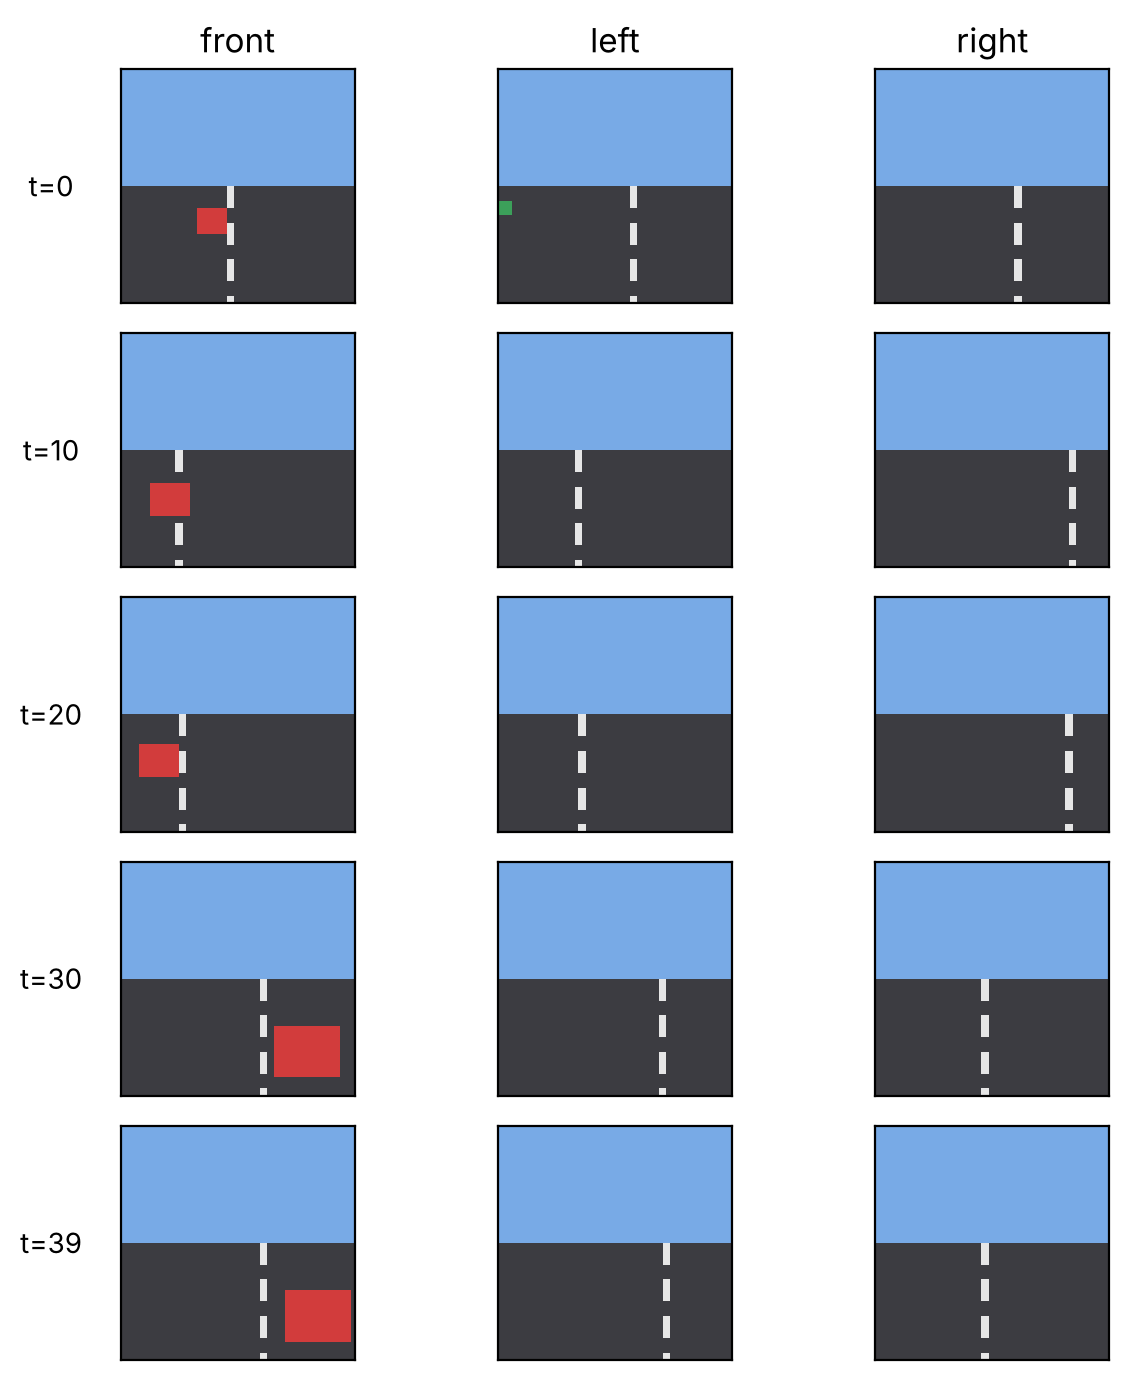

In [2]:
# 시간에 따른 3개 카메라 뷰 보기 (몇 개 타임스텝만 샘플링)
timesteps = [0, 10, 20, 30, 39]
fig, axes = plt.subplots(len(timesteps), W.NUM_CAMS, figsize=(W.NUM_CAMS * 2.2, len(timesteps) * 1.4))

for row, t in enumerate(timesteps):
    for cam in range(W.NUM_CAMS):
        ax = axes[row, cam]
        ax.imshow(W.frame_to_uint8(frames[t, cam]))
        if row == 0:
            ax.set_title(W.CAM_NAMES[cam])
        if cam == 0:
            ax.set_ylabel(f"t={t}", rotation=0, labelpad=25, va="center")
        ax.set_xticks([]); ax.set_yticks([])

plt.tight_layout()
plt.show()


위 그림에서 눈여겨볼 점:
- **front/left/right가 같은 세계를 다른 각도에서** 보여줍니다 — 빨간/초록 네모(앞차 2대)가
  카메라마다 다른 위치·크기로 보입니다.
- ego가 조향하면 (차선을 바꾸면) 차선 마커 전체가 좌우로 스크롤되는 걸 볼 수 있습니다 —
  이게 "ego-motion이 관측에 반영된다"는 뜻이고, 월드 모델이 action을 입력으로 받아야 하는
  이유입니다.


In [3]:
# 여러 에피소드로 구성된 학습용 Dataset
train_ds = W.WMSequenceDataset(num_episodes=64, T=40, base_seed=1000)
val_ds = W.WMSequenceDataset(num_episodes=8, T=40, base_seed=5000)

frames_i, actions_i, states_i = train_ds[0]
print("dataset size:", len(train_ds), "(train) /", len(val_ds), "(val)")
print("one episode -> frames:", frames_i.shape, "actions:", actions_i.shape)


dataset size: 64 (train) / 8 (val)
one episode -> frames: torch.Size([40, 3, 3, 64, 64]) actions: torch.Size([40, 2])


### 실제 데이터로 넘어갈 때

이 Dataset 클래스(`WMSequenceDataset`)는 `video-classification/` 폴더에서 쓴 패턴과 동일하게
"하나의 아이템 = 하나의 시퀀스"로 구성되어 있습니다. 나중에 실제 멀티카메라 로그 데이터로
바꾸고 싶다면:

- `simulate_episode()`를 "디스크에서 N개 카메라 영상 + CAN 로그를 읽어서 (frames, actions)로
  변환하는 함수"로 교체
- 모델 쪽(`wm_toy.WorldModel`)은 입력 shape(`(T, NUM_CAMS, 3, H, W)`, `(T, ACTION_DIM)`)만
  맞으면 그대로 재사용 가능

다음 노트북에서 이 데이터를 받는 모델 구조를 뜯어봅니다.
